# Starting Spark

In [1]:
import shutil
from pyspark.sql import *
from pyspark.sql.types import *
from delta import *
from pathlib import Path
from pyspark.sql import functions as F


builder = (
    SparkSession
        .builder
        .appName("Pollen")
        .config("spark.sql.extensions", "io.delta.sql.DeltaSparkSessionExtension")
        .config("spark.sql.catalog.spark_catalog", "org.apache.spark.sql.delta.catalog.DeltaCatalog")
)

# Utworzenie sesji.
session = configure_spark_with_delta_pip(builder).getOrCreate()

# Konfiguracja dodatkowych parametrów sesji po jej utworzeniu.
session.conf.set("spark.sql.shuffle.partitions", "20")

:: loading settings :: url = jar:file:/opt/spark-4.2.0-bin-hadoop3/jars/ivy-2.5.3.jar!/org/apache/ivy/core/settings/ivysettings.xml
Ivy Default Cache set to: /home/Binny/.ivy2.5.2/cache
The jars for the packages stored in: /home/Binny/.ivy2.5.2/jars
io.delta#delta-spark_4.2_2.13 added as a dependency
:: resolving dependencies :: org.apache.spark#spark-submit-parent-1ffe06ec-3c5d-433d-b465-326c988f8d4c;1.0
	confs: [default]
	found io.delta#delta-spark_4.2_2.13;4.4.1 in central
	found io.delta#delta-storage;4.4.1 in central
	found io.unitycatalog#unitycatalog-client;0.6.0 in central
	found org.slf4j#slf4j-api;2.0.13 in central
	found org.apache.logging.log4j#log4j-slf4j2-impl;2.25.3 in central
	found org.apache.logging.log4j#log4j-api;2.25.3 in central
	found com.google.code.findbugs#jsr305;3.0.2 in central
	found io.unitycatalog#unitycatalog-hadoop;0.6.0 in central
	found org.apache.logging.log4j#log4j-core;2.25.3 in central
	found io.delta#delta-kernel-api;4.4.1 in central
	found org.r

### Reading data

In [2]:
pollen_path = 'data/delta/pollen_historical'
pollen_df = (
    session.read
    .format("delta")
    .load(pollen_path)
)

# Verification: Print row count and schema to confirm data is loaded correctly
print(f"Total rows loaded: {pollen_df.count()}")
pollen_df.printSchema()

26/11/08 17:07:02 WARN SparkStringUtils: Truncated the string representation of a plan since it was too large. This behavior can be adjusted by setting 'spark.sql.debug.maxToStringFields'.


Total rows loaded: 142247
root
 |-- station_abbr: string (nullable = true)
 |-- reference_timestamp: string (nullable = true)
 |-- kaalnud0: double (nullable = true)
 |-- kabetud0: double (nullable = true)
 |-- kacoryd0: double (nullable = true)
 |-- kafagud0: double (nullable = true)
 |-- kafraxd0: double (nullable = true)
 |-- kaquerd0: double (nullable = true)
 |-- khpoacd0: double (nullable = true)



In [3]:
meteo_path = "data/delta/meteo_historical"
meteo_df = (
    session.read
    .format("delta")
    .load(meteo_path)
)

print(f"Total rows loaded: {meteo_df.count()}")
meteo_df.printSchema()

Total rows loaded: 636556
root
 |-- station_abbr: string (nullable = true)
 |-- reference_timestamp: string (nullable = true)
 |-- tre200d0: double (nullable = true)
 |-- tre200dx: double (nullable = true)
 |-- tre200dn: double (nullable = true)
 |-- tre005d0: double (nullable = true)
 |-- tre005dx: double (nullable = true)
 |-- tre005dn: double (nullable = true)
 |-- ure200d0: double (nullable = true)
 |-- pva200d0: double (nullable = true)
 |-- prestad0: double (nullable = true)
 |-- pp0qffd0: double (nullable = true)
 |-- ppz850d0: double (nullable = true)
 |-- ppz700d0: string (nullable = true)
 |-- pp0qnhd0: double (nullable = true)
 |-- fkl010d0: double (nullable = true)
 |-- fkl010d1: double (nullable = true)
 |-- fu3010d0: double (nullable = true)
 |-- fu3010d1: double (nullable = true)
 |-- fkl010d3: double (nullable = true)
 |-- fu3010d3: double (nullable = true)
 |-- wcc006d0: double (nullable = true)
 |-- rre150d0: double (nullable = true)
 |-- rka150d0: double (nullable = 

In [4]:
phenology_path = "data/delta/phenology"
phenology_df = (
    session.read
    .format("delta")
    .load(phenology_path)
)

print(f"Total rows loaded: {phenology_df.count()}")
phenology_df.printSchema()

Total rows loaded: 580
root
 |-- station_abbr: string (nullable = true)
 |-- reference_timestamp: string (nullable = true)
 |-- maesh13d: double (nullable = true)
 |-- maesh60d: double (nullable = true)
 |-- maesh65d: double (nullable = true)
 |-- maesh94d: double (nullable = true)
 |-- maesh95d: double (nullable = true)
 |-- mfags13d: double (nullable = true)
 |-- mfags94d: double (nullable = true)
 |-- mfags95d: double (nullable = true)
 |-- macep13d: double (nullable = true)
 |-- macep94d: double (nullable = true)
 |-- msora13d: double (nullable = true)
 |-- msora60d: double (nullable = true)
 |-- msora65d: double (nullable = true)
 |-- msora87d: double (nullable = true)
 |-- msora94d: double (nullable = true)
 |-- msora95d: double (nullable = true)
 |-- mcora13d: double (nullable = true)
 |-- mcora60d: double (nullable = true)
 |-- mcora65d: double (nullable = true)
 |-- mtilp13d: double (nullable = true)
 |-- mtilp60d: double (nullable = true)
 |-- mtilp65d: double (nullable = tru

# Cleaning data

## Pollen

In [5]:
from pyspark.sql import functions as F

# 1. Automatically filter columns that are of type 'double' or 'float' (where NaNs can occur)
numerical_cols = [c for c, dtype in pollen_df.dtypes if dtype in ('double', 'float')]

print(f"Checking numerical columns: {numerical_cols}")

# 2. Count NaNs and nulls only for those numerical columns
nan_counts = pollen_df.select([
    F.count(F.when(F.col(c).isNaN(), c)).alias(c)
    for c in numerical_cols
])

nan_counts.show(truncate=False)

Checking numerical columns: ['kaalnud0', 'kabetud0', 'kacoryd0', 'kafagud0', 'kafraxd0', 'kaquerd0', 'khpoacd0']
+--------+--------+--------+--------+--------+--------+--------+
|kaalnud0|kabetud0|kacoryd0|kafagud0|kafraxd0|kaquerd0|khpoacd0|
+--------+--------+--------+--------+--------+--------+--------+
|0       |0       |0       |0       |0       |0       |0       |
+--------+--------+--------+--------+--------+--------+--------+



In [6]:
from pyspark.sql import functions as F
from pyspark.sql.window import Window

# 1. Define window partitioned by station and ordered by timestamp
window_spec = Window.partitionBy("station_abbr").orderBy("reference_timestamp")

# Choose the column you want to inspect
target_columns = ["kaalnud0", "kabetud0", "kacoryd0", "kafagud0", "kafraxd0", "kaquerd0", "khpoacd0"]

# 2. Flag null/NaN and create a unique ID for each consecutive streak
for target_col in target_columns:
    df_streaks = (
        pollen_df
        # Flag whether the value is null or NaN
        .withColumn("is_null", F.col(target_col).isNull() | F.isnan(F.col(target_col)))
        # Detect when the null status changes from the previous row
        .withColumn("prev_is_null", F.lag("is_null", 1).over(window_spec))
        .withColumn(
            "streak_change",
            F.when((F.col("is_null") != F.col("prev_is_null")) | F.col("prev_is_null").isNull(), 1).otherwise(0)
        )
        # Assign a unique group ID to each consecutive block
        .withColumn("streak_id", F.sum("streak_change").over(window_spec))
    )

    # 3. Aggregate to count the length of each missing data streak
    streak_lengths = (
        df_streaks
        .filter(F.col("is_null") == True)
        .groupBy("station_abbr", "streak_id")
        .agg(F.count("*").alias("consecutive_missing_count"))
    )

    # 4. Filter for streaks greater than 3
    long_gaps = streak_lengths.filter(F.col("consecutive_missing_count") > 3)

    print(f"Found {long_gaps.count()} gaps longer than 3 consecutive missing points for {target_col}:")

Found 0 gaps longer than 3 consecutive missing points for kaalnud0:
Found 0 gaps longer than 3 consecutive missing points for kabetud0:
Found 0 gaps longer than 3 consecutive missing points for kacoryd0:
Found 0 gaps longer than 3 consecutive missing points for kafagud0:
Found 0 gaps longer than 3 consecutive missing points for kafraxd0:
Found 0 gaps longer than 3 consecutive missing points for kaquerd0:
Found 0 gaps longer than 3 consecutive missing points for khpoacd0:


In [7]:
# 1. Define windows for forward-fill and backward-fill (for any leading gaps)
fw_window = (
    Window.partitionBy("station_abbr")
    .orderBy("reference_timestamp")
    .rowsBetween(Window.unboundedPreceding, Window.currentRow)
)

bw_window = (
    Window.partitionBy("station_abbr")
    .orderBy(F.col("reference_timestamp").desc())
    .rowsBetween(Window.unboundedPreceding, Window.currentRow)
)

for col in target_columns:
    pollen_df = (
        pollen_df
        # Step 1: Turn NaN into a true SQL NULL so Spark recognizes it as missing
        .withColumn(col, F.when(F.isnan(F.col(col)), None).otherwise(F.col(col)))
        # Step 2: Apply forward-fill, with a fallback to backward-fill for start-of-series gaps
        .withColumn(
            col,
            F.coalesce(
                F.col(col),
                F.last(F.col(col), ignorenulls=True).over(fw_window),
                F.last(F.col(col), ignorenulls=True).over(bw_window)
            )
        )
    )

# 3. Verify that all NaNs and nulls are successfully gone
print("Verification - Remaining missing values:")
verification_counts = pollen_df.select([
    F.count(F.when(F.col(c).isNull() | F.isnan(F.col(c)), c)).alias(c)
    for c in target_columns
])
verification_counts.show(truncate=False)

Verification - Remaining missing values:


+--------+--------+--------+--------+--------+--------+--------+
|kaalnud0|kabetud0|kacoryd0|kafagud0|kafraxd0|kaquerd0|khpoacd0|
+--------+--------+--------+--------+--------+--------+--------+
|0       |0       |0       |0       |0       |0       |0       |
+--------+--------+--------+--------+--------+--------+--------+



In [8]:
# 1. Identify columns that end with '1'
cols_to_drop = ["kaalnud1", "kabetud1", "kacoryd1", "kafagud1", "kafraxd1", "kaquerd1", "khpoacd1"]

# 2. Drop those columns from the DataFrame
spark_final_df = pollen_df.drop(*cols_to_drop)

# Verify remaining columns
print(f"Remaining columns: {spark_final_df.columns}")

# 4. Save the processed DataFrame into Delta format
(
    spark_final_df.write
    .format("delta")
    .mode("overwrite")
    .option("overwriteSchema", "true")  # Forces Delta to update the table schema with the dropped columns
    .save(pollen_path)
)

print(f"Successfully saved filtered and cleaned data to Delta table at: {pollen_path}")

Remaining columns: ['station_abbr', 'reference_timestamp', 'kaalnud0', 'kabetud0', 'kacoryd0', 'kafagud0', 'kafraxd0', 'kaquerd0', 'khpoacd0']


Successfully saved filtered and cleaned data to Delta table at: data/delta/pollen_historical


# EDA

## Pollen

In [9]:
pollen_df.describe().show()

+-------+------------+-------------------+------------------+------------------+------------------+------------------+------------------+------------------+------------------+
|summary|station_abbr|reference_timestamp|          kaalnud0|          kabetud0|          kacoryd0|          kafagud0|          kafraxd0|          kaquerd0|          khpoacd0|
+-------+------------+-------------------+------------------+------------------+------------------+------------------+------------------+------------------+------------------+
|  count|      142247|             142247|            142247|            142247|            142247|            142247|            142247|            142247|            142247|
|   mean|        NULL|               NULL| 8.490273960083517|22.688520671789213| 6.546992203702011|  3.97072697490984|15.200545529958452|10.052732219308668|19.937003943844157|
| stddev|        NULL|               NULL|49.079298798014506|139.27656758631704|34.293328270480266|28.684914488060326| 8

In [10]:
# 1. Convert string timestamp to a true Spark timestamp using your exact format
spark_parsed_df = pollen_df.withColumn(
    "parsed_timestamp",
    F.to_timestamp(F.col("reference_timestamp"), "dd.MM.yyyy HH:mm")
)

# 2. Filter for the 2010s (2010–2019) directly in Spark to save memory
pollen_2010s_df = spark_parsed_df.filter(
    (F.year(F.col("parsed_timestamp")) >= 2010) &
    (F.year(F.col("parsed_timestamp")) <= 2019)
)

print(f"Filtered 2010s row count: {pollen_2010s_df.count()}")

Filtered 2010s row count: 35471


/home/Binny/Projects/Pollen/.venv/lib64/python3.12/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
/home/Binny/Projects/Pollen/.venv/lib64/python3.12/site-packages/pyspark/sql/pandas/types.py:778: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


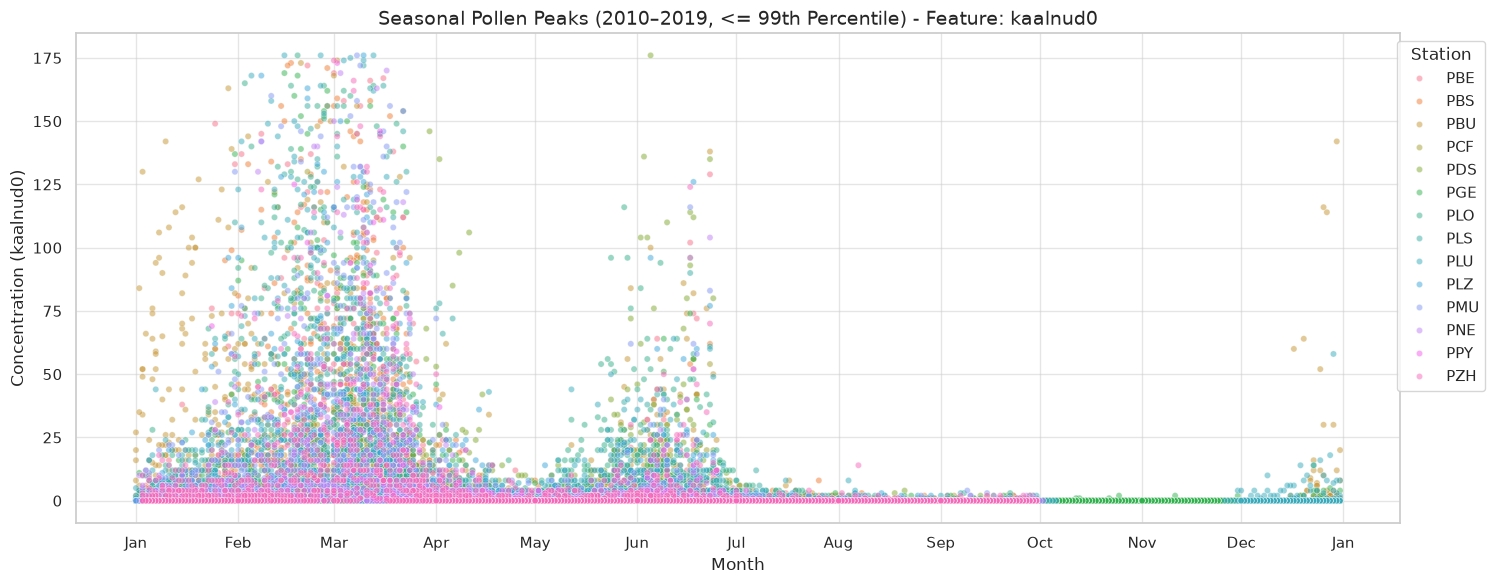

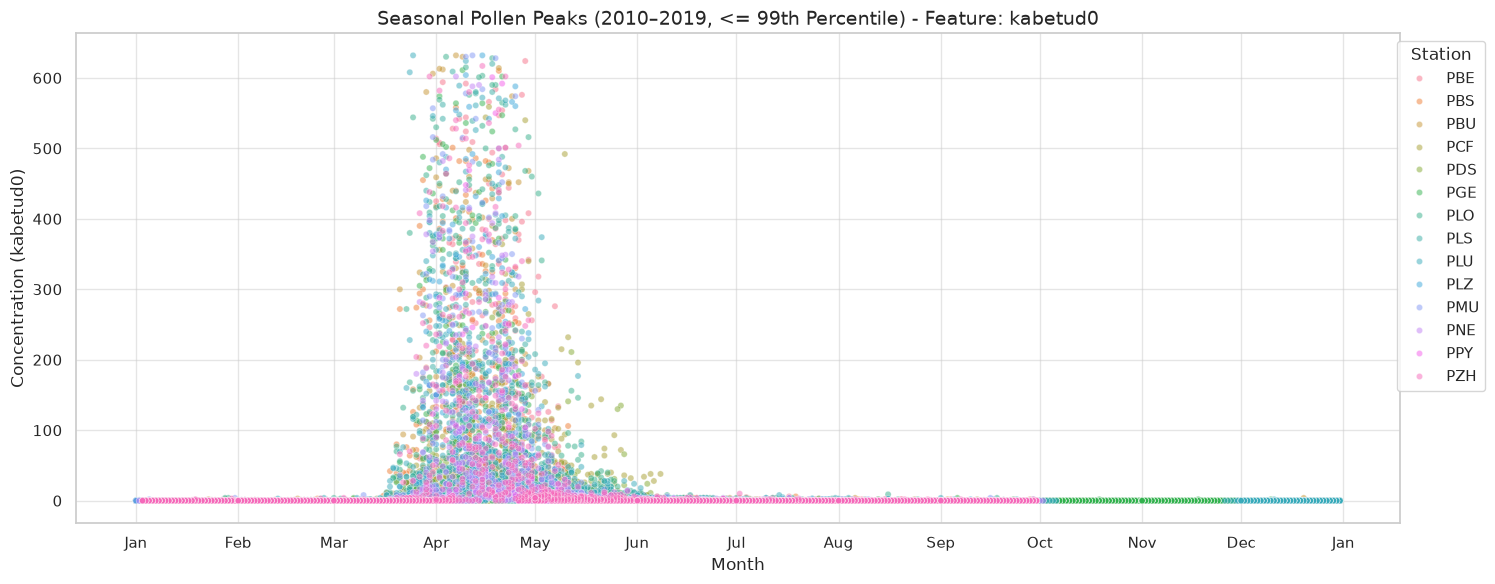

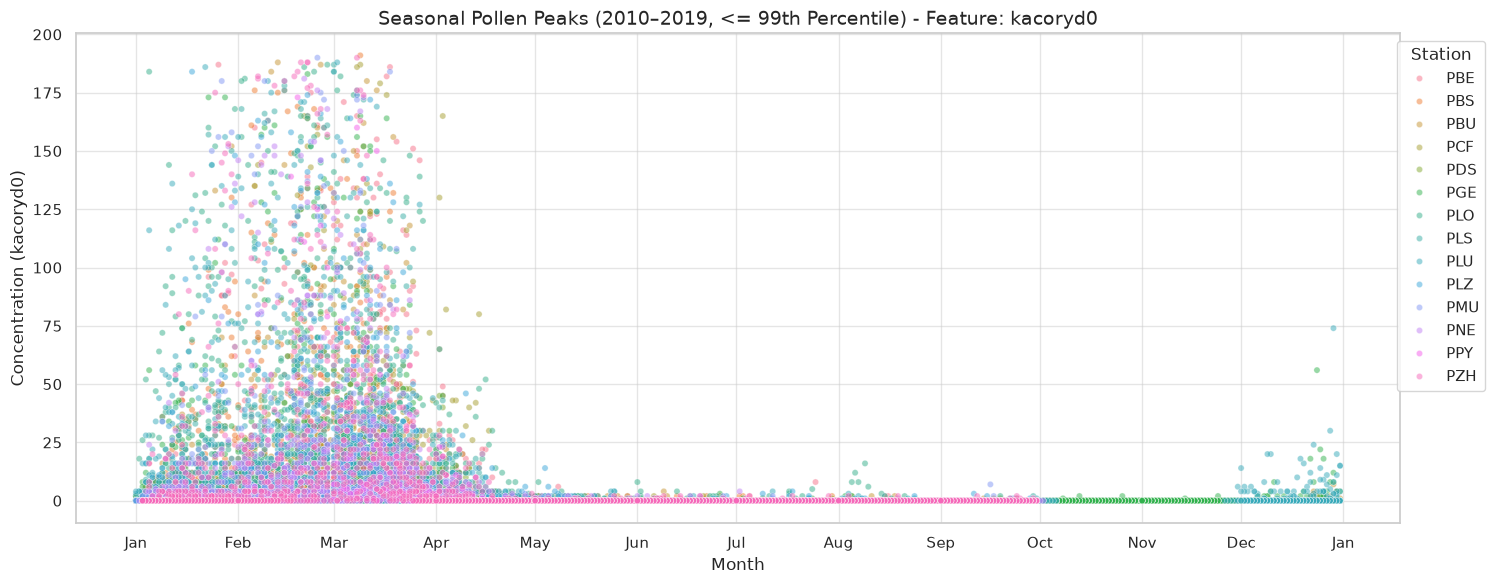

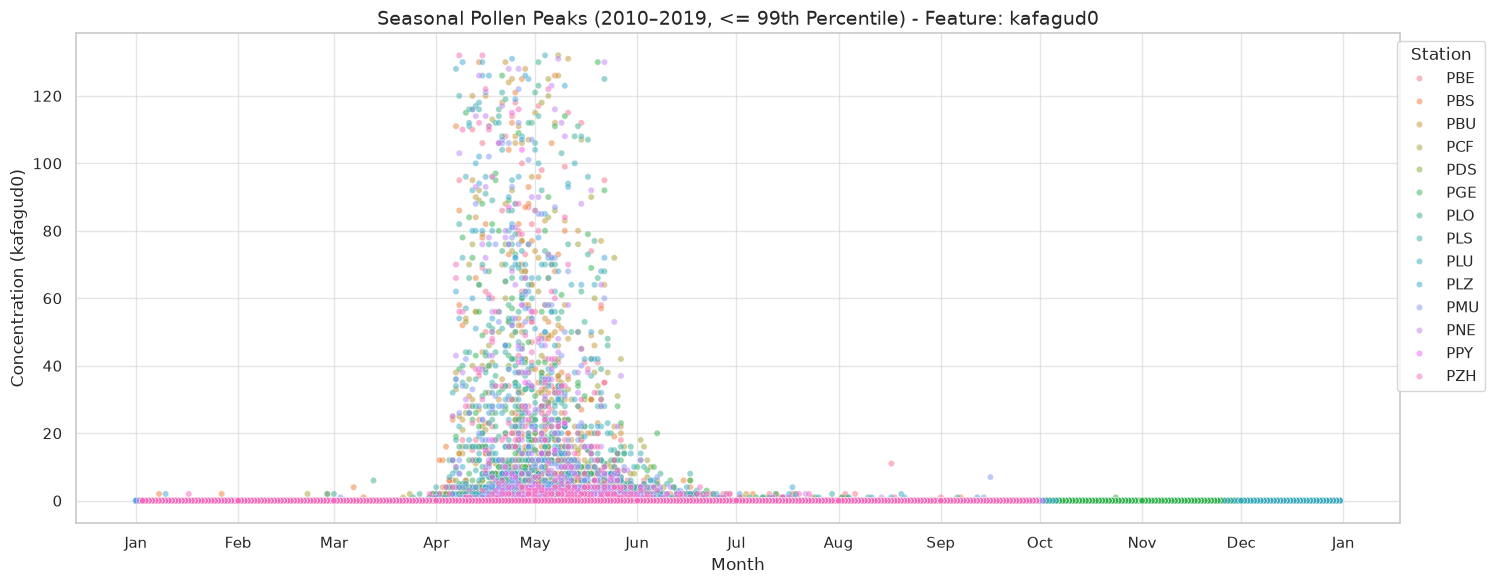

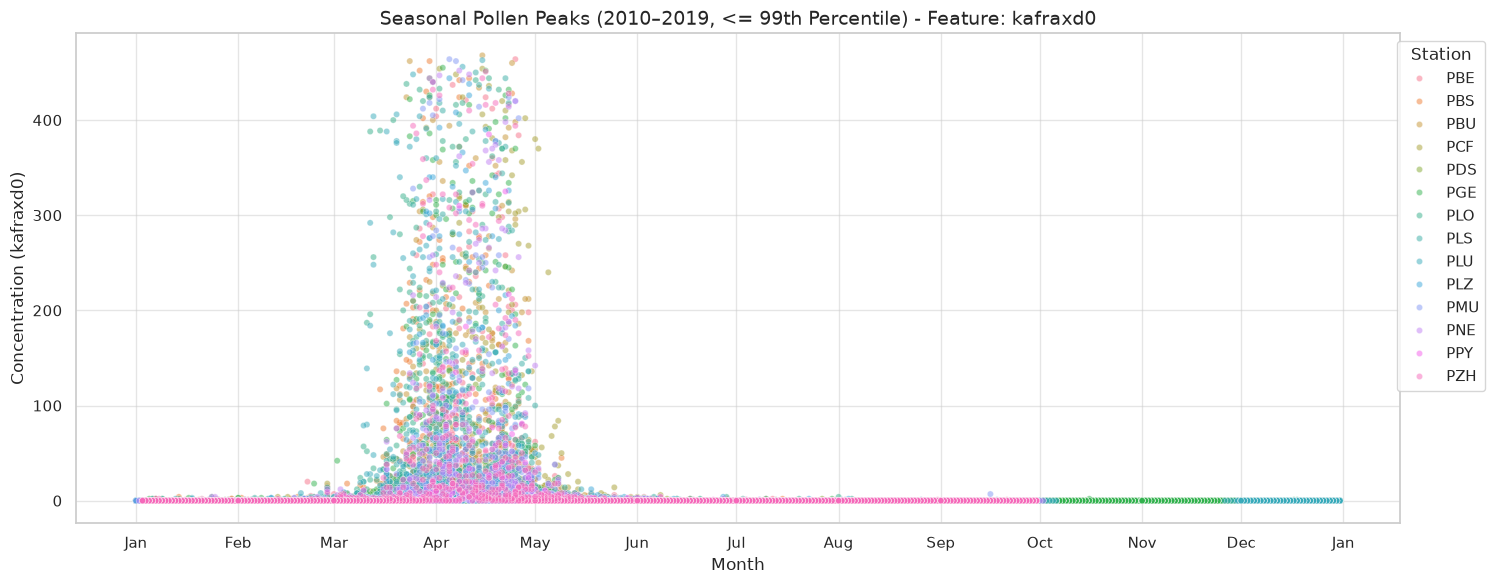

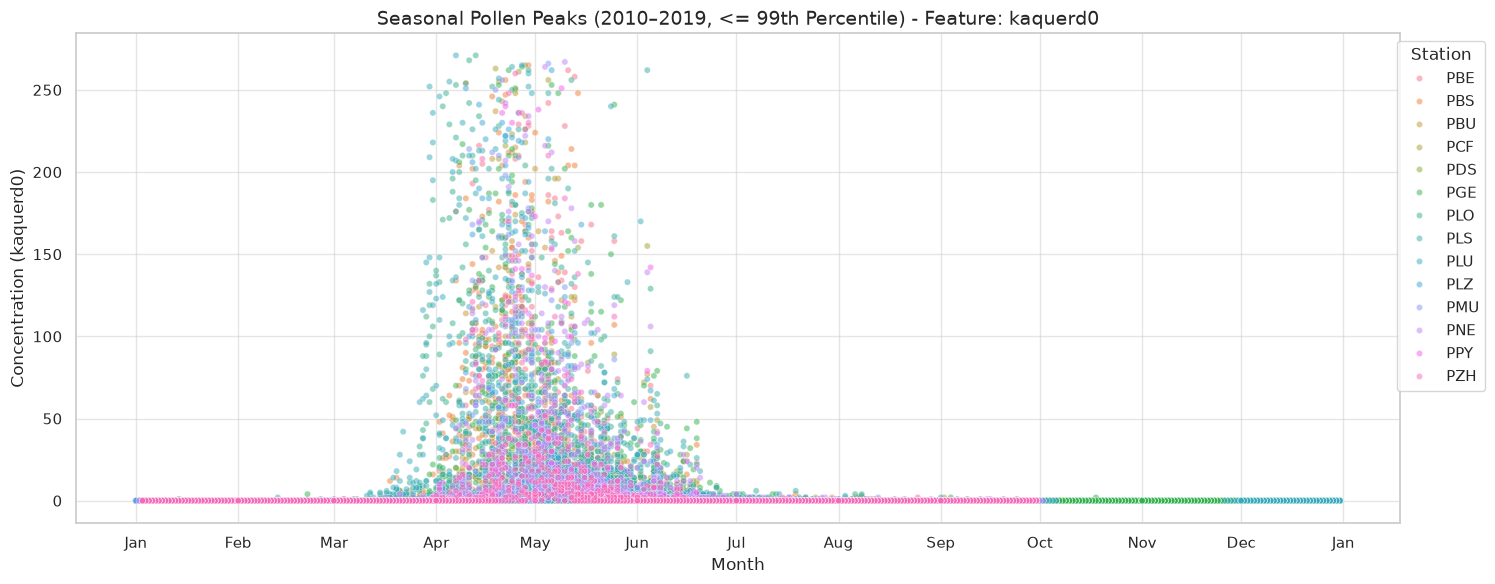

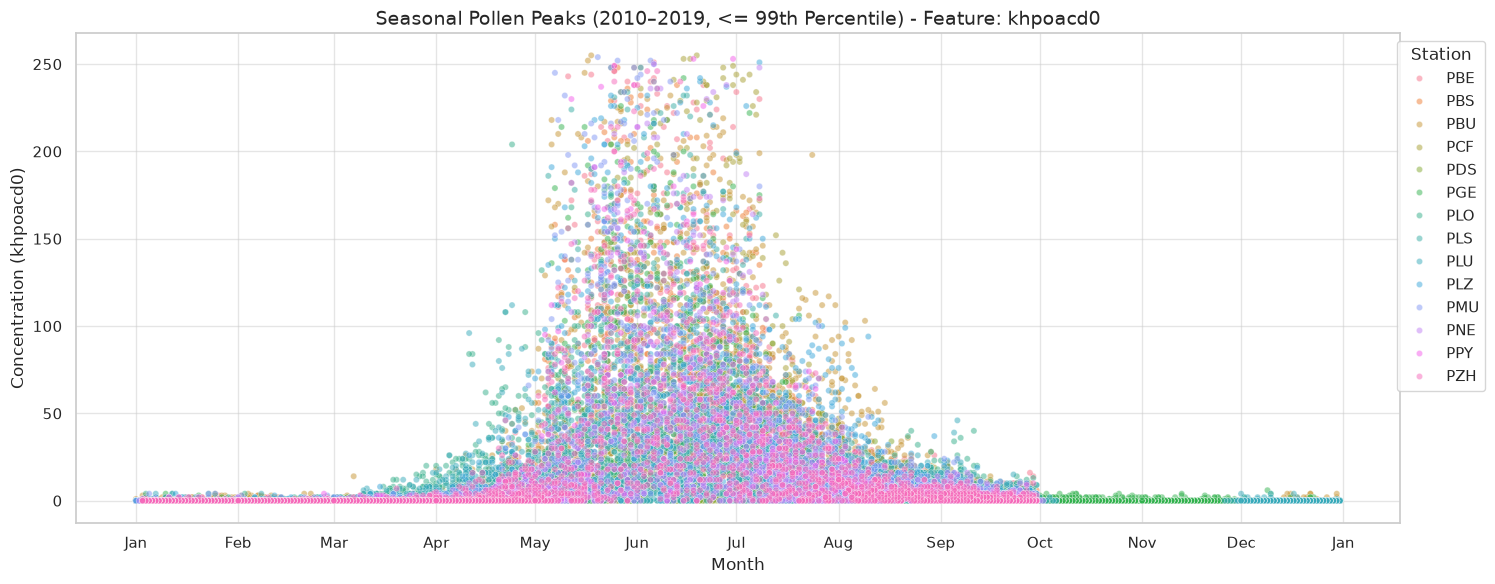

In [11]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
import pandas as pd
import numpy as np
sns.set_theme(style="whitegrid", palette="deep")

# 1. Identify pollen features (excluding metadata columns)
exclude_cols = {"station_abbr", "reference_timestamp", "parsed_timestamp"}
pollen_features = [c for c in pollen_2010s_df.columns if c not in exclude_cols]

# 2. Pull only the filtered data into Pandas
pollen_plot_df = pollen_2010s_df.toPandas()

# Ensure it's datetime type in Pandas (using your exact format to avoid warnings)
pollen_plot_df["parsed_timestamp"] = pd.to_datetime(pollen_plot_df["parsed_timestamp"])

# 3. Strip the year to a dummy year (2000) for seasonal overlay
pollen_plot_df["date_no_year"] = pollen_plot_df["parsed_timestamp"].apply(lambda dt: dt.replace(year=2000) if pd.notnull(dt) else dt)

# 4. Loop through each pollen feature and generate a separate dot plot
for feature in pollen_features:
    # 1. Calculate the 99th percentile threshold for the current feature
    p99_threshold = pollen_plot_df[feature].quantile(0.99)

    # 2. Filter out outliers (keep only values <= 99th percentile)
    ppdf_filtered = pollen_plot_df[pollen_plot_df[feature] <= p99_threshold]

    # 3. Create the plot for the filtered data
    plt.figure(figsize=(15, 6))

    sns.scatterplot(
        data=ppdf_filtered,
        x="date_no_year",
        y=feature,
        hue="station_abbr",
        alpha=0.5,
        s=20
    )

    # Format x-axis to show month names cleanly (Jan, Feb, Mar...)
    ax = plt.gca()
    ax.xaxis.set_major_locator(mdates.MonthLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%b'))

    plt.title(f"Seasonal Pollen Peaks (2010–2019, <= 99th Percentile) - Feature: {feature}", fontsize=14)
    plt.xlabel("Month", fontsize=12)
    plt.ylabel(f"Concentration ({feature})", fontsize=12)
    plt.xticks(rotation=0)
    plt.legend(bbox_to_anchor=(1.07, 1), loc="upper right", title="Station")
    plt.tight_layout()
    plt.show()

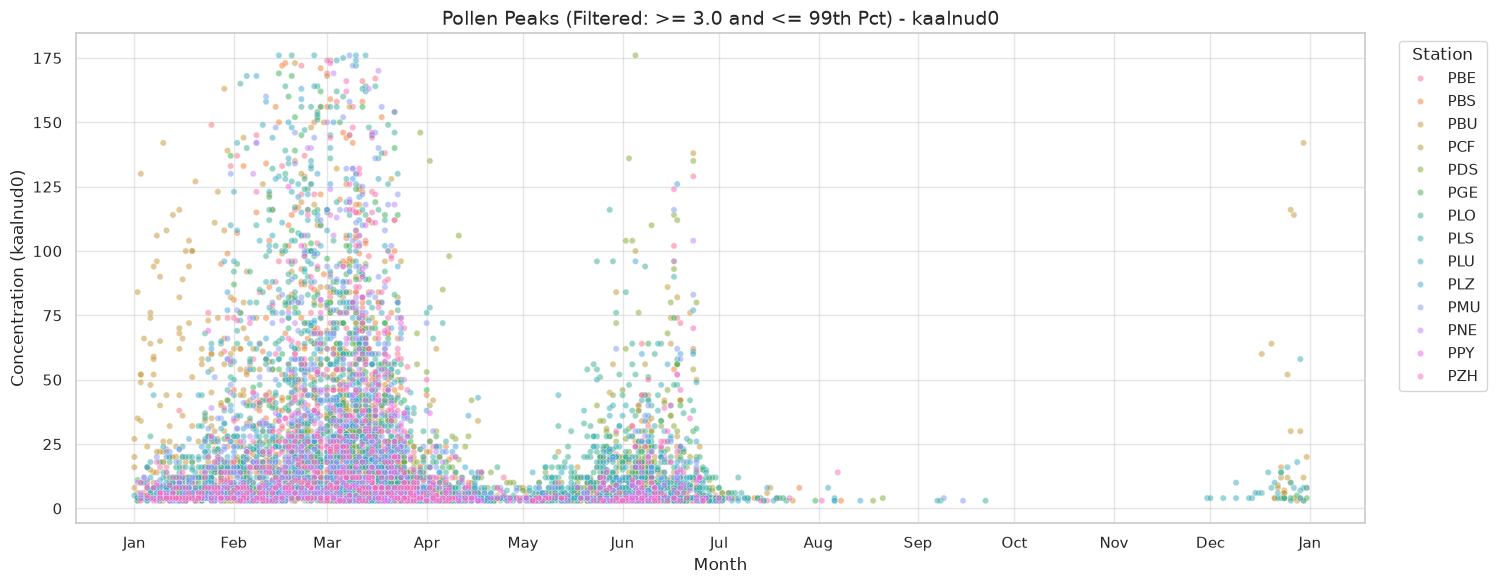

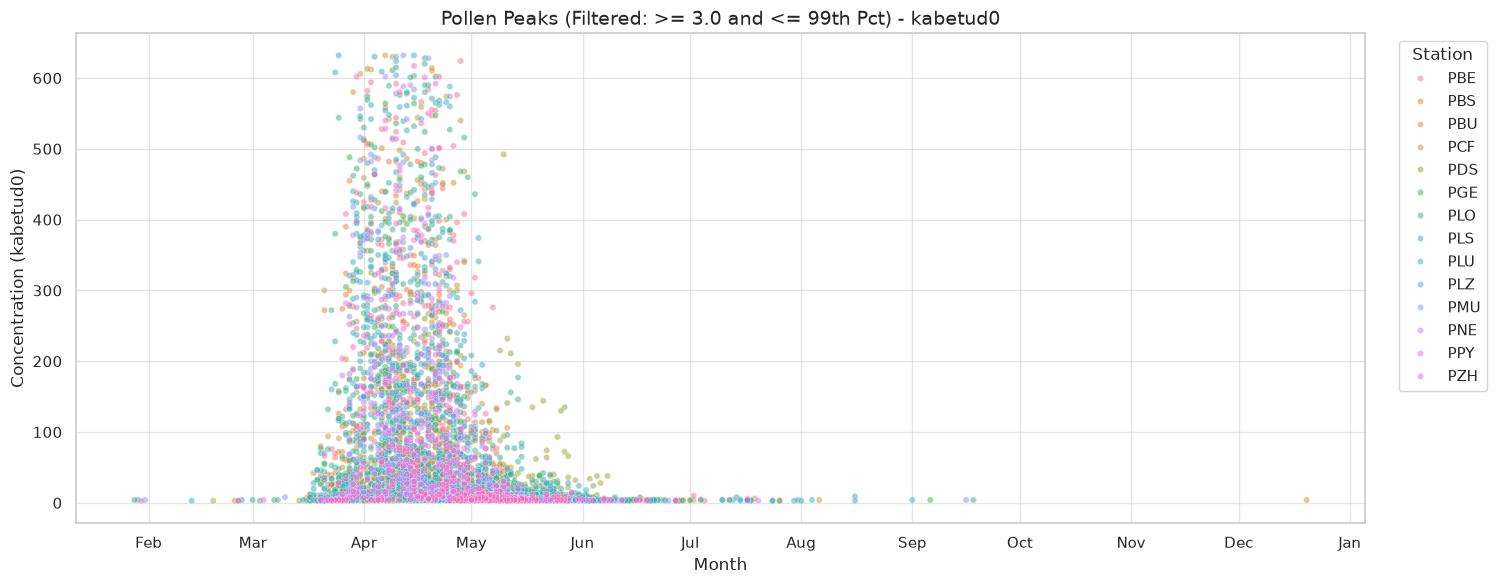

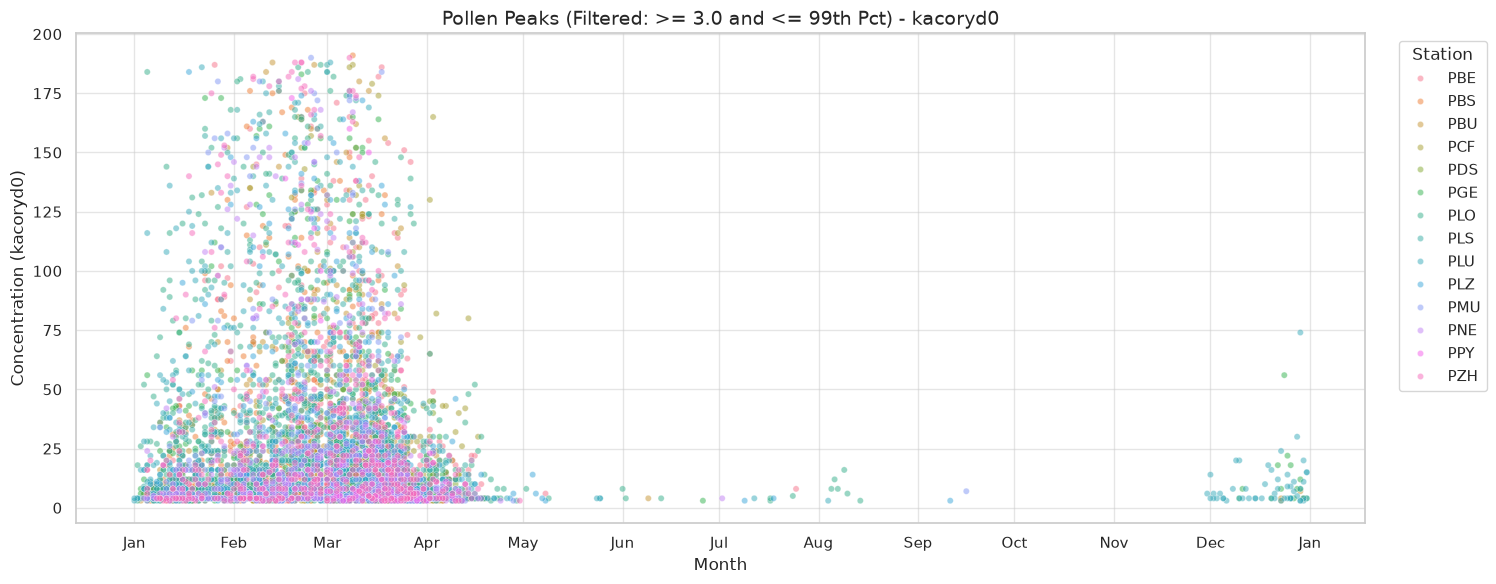

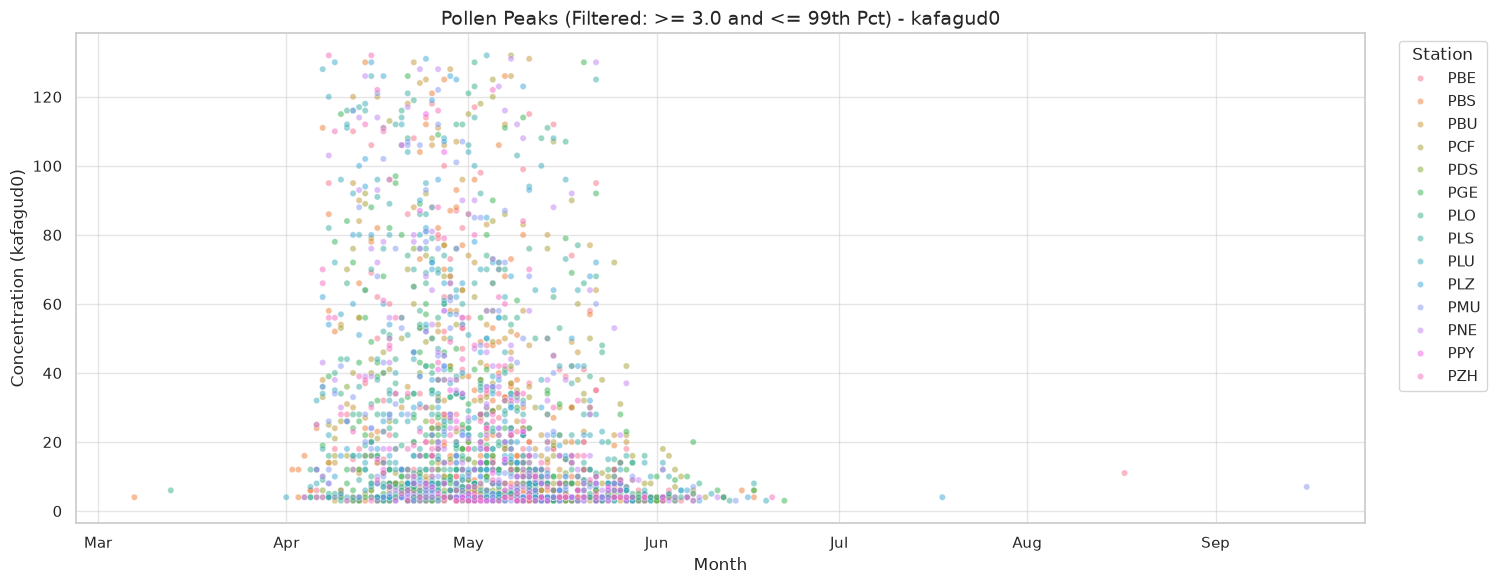

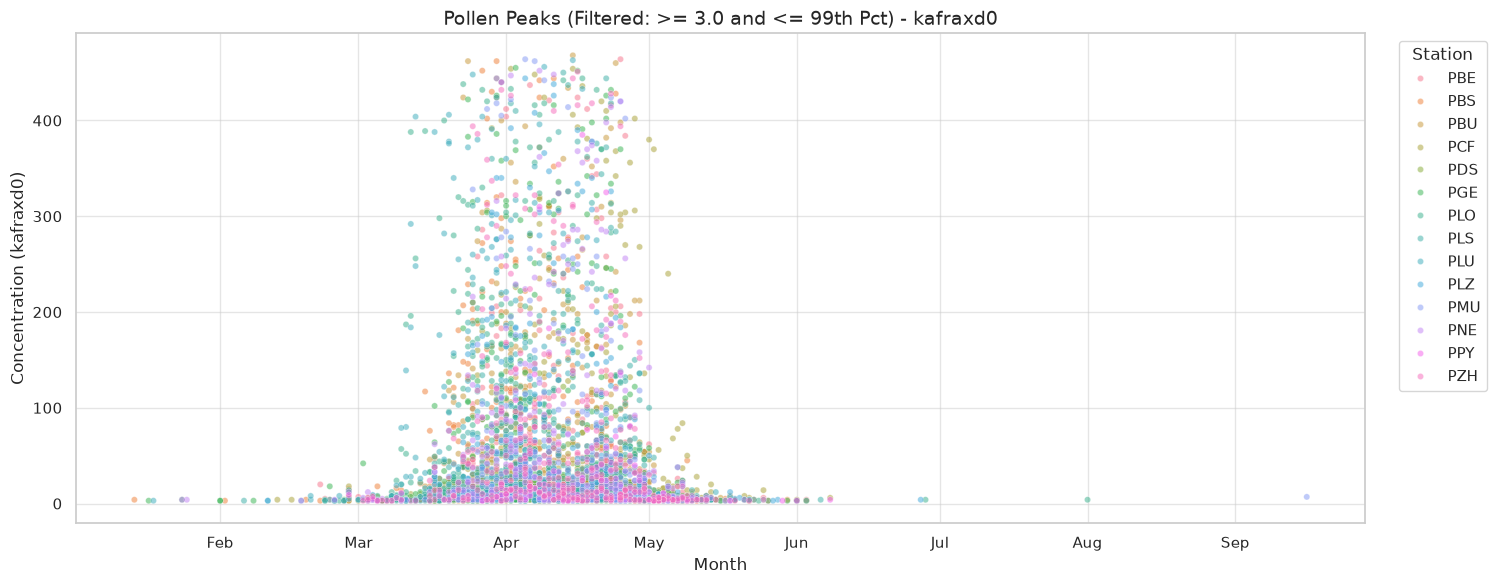

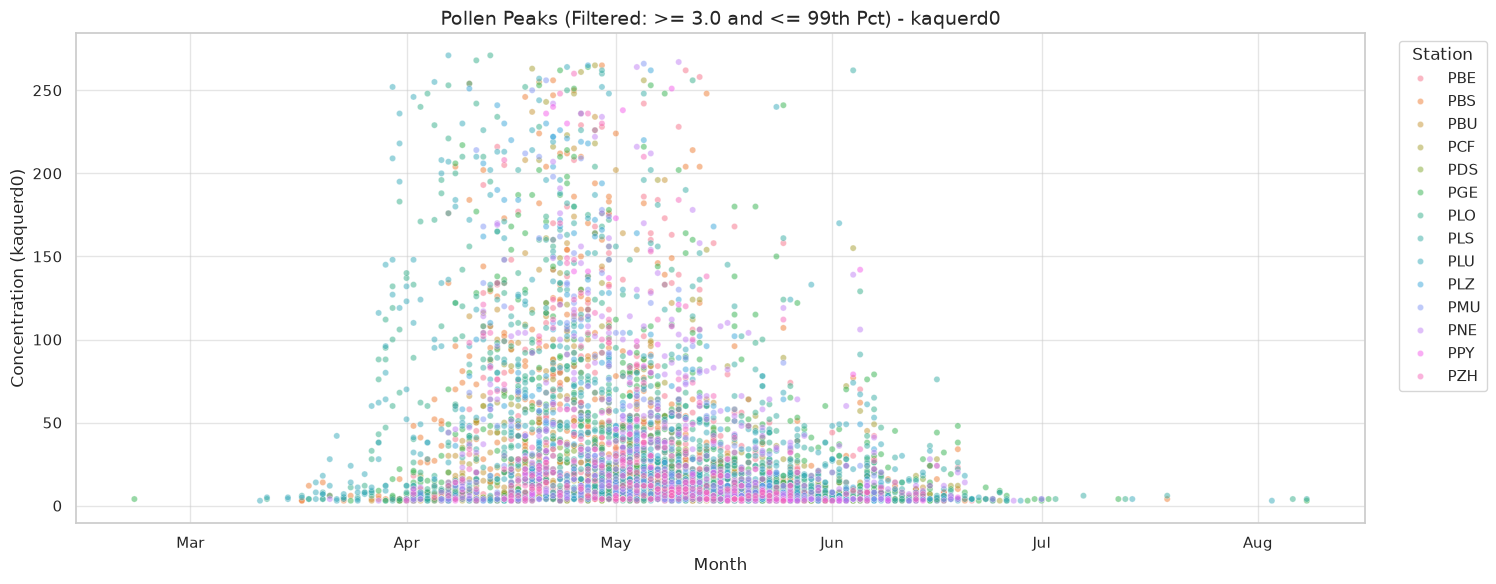

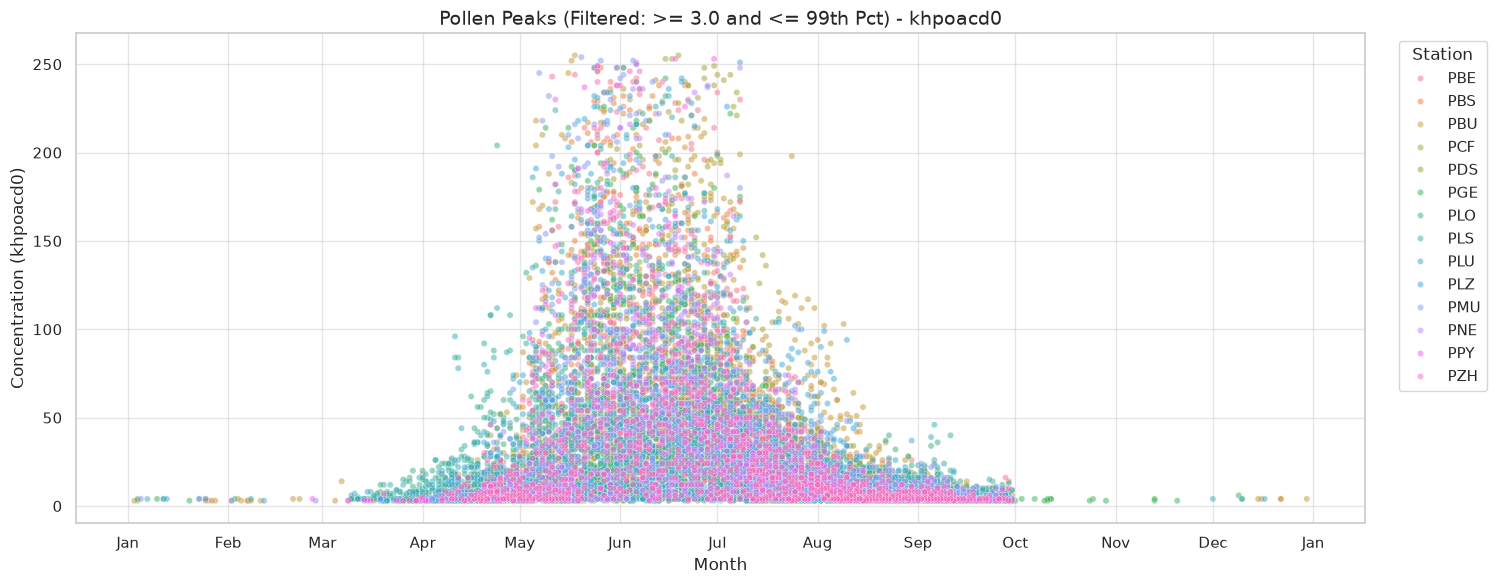

In [12]:
for feature in pollen_features:
    # 1. Define your lower threshold limit
    lower_limit = 3.0
    # 2. Filter the DataFrame (keep only values >= lower limit, and keep upper 99th percentile cap)
    upper_limit = pollen_plot_df[feature].quantile(0.99)

    ppdf_filtered = pollen_plot_df[
        (pollen_plot_df[feature] >= lower_limit) &
        (pollen_plot_df[feature] <= upper_limit)
        ]

    # 3. Create scatter plot with the cleaned subset
    plt.figure(figsize=(15, 6))
    sns.scatterplot(
        data=ppdf_filtered,
        x="date_no_year",
        y=feature,
        hue="station_abbr",
        alpha=0.5,
        s=20
    )

    ax = plt.gca()
    ax.xaxis.set_major_locator(mdates.MonthLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%b'))

    plt.title(f"Pollen Peaks (Filtered: >= {lower_limit} and <= 99th Pct) - {feature}", fontsize=14)
    plt.xlabel("Month", fontsize=12)
    plt.ylabel(f"Concentration ({feature})", fontsize=12)
    plt.legend(bbox_to_anchor=(1.1, 1), loc="upper right", title="Station")
    plt.tight_layout()
    plt.show()

## Phenology

In [13]:
from data_loader import load_or_download_csv

phenology_params = load_or_download_csv("https://data.geo.admin.ch/ch.meteoschweiz.ogd-phenology/",
                                        "ogd-phenology_meta_parameters.csv",
                                        "data/meta")
pollen_params = load_or_download_csv("https://data.geo.admin.ch/ch.meteoschweiz.ogd-pollen/",
                                     "ogd-pollen_meta_parameters.csv",
                                     "data/meta")

print(phenology_params.columns)
print(pollen_params.columns)

Checking server for updates: https://data.geo.admin.ch/ch.meteoschweiz.ogd-phenology/ogd-phenology_meta_parameters.csv
File is up to date (304 Not Modified). Loading local file from: data/meta/ogd-phenology_meta_parameters.csv
Checking server for updates: https://data.geo.admin.ch/ch.meteoschweiz.ogd-pollen/ogd-pollen_meta_parameters.csv
File is up to date (304 Not Modified). Loading local file from: data/meta/ogd-pollen_meta_parameters.csv
Index(['parameter_shortname', 'parameter_description_de',
       'parameter_description_fr', 'parameter_description_it',
       'parameter_description_en', 'parameter_group_de', 'parameter_group_fr',
       'parameter_group_it', 'parameter_group_en', 'parameter_granularity',
       'parameter_decimals', 'parameter_datatype', 'parameter_unit'],
      dtype='str')
Index(['parameter_shortname', 'parameter_description_de',
       'parameter_description_fr', 'parameter_description_it',
       'parameter_description_en', 'parameter_group_de', 'parameter_g

In [14]:
# 1. Extract scientific name and genus for pollen parameters
pollen_params['scientific_name'] = pollen_params['parameter_description_en'].str.split('/').str[-1].str.strip()
pollen_params['genus'] = pollen_params['scientific_name'].str.split().str[0]

# 2. Extract scientific name and genus for phenology parameters
phenology_params['scientific_name'] = phenology_params['parameter_description_en'].str.split('/').str[-1].str.strip()
phenology_params['genus'] = phenology_params['scientific_name'].str.split().str[0]

# 3. Get the list of unique genera present in pollen parameters
unique_pollen_genera = pollen_params['genus'].unique()

# 4. Find corresponding rows in phenology parameters
matching_pheno_params = phenology_params[phenology_params['genus'].isin(unique_pollen_genera)]

# 5. Concatenate them together vertically so the column structure remains identical
combined_params = pd.concat([pollen_params, matching_pheno_params], ignore_index=True)

print(f"Total rows in combined parameter table: {len(combined_params)}")
print(f"Total columns (unchanged): {len(combined_params.columns)}")

Total rows in combined parameter table: 39
Total columns (unchanged): 15


In [15]:
# 1. Extract the list of relevant shortnames as a standard Python list from your Pandas metadata
relevant_phenology_params = matching_pheno_params['parameter_shortname'].tolist()

# 2. Identify base metadata columns you always want to keep
base_cols = ['station_abbr', 'reference_timestamp']

# 3. Find which of the relevant parameters actually exist as columns in your Spark dataframe
columns_to_keep = base_cols + [c for c in relevant_phenology_params if c in phenology_df.columns]

print(f"Columns to keep from phenology dataframe: {columns_to_keep}")

# 4. Select only those columns in PySpark
relevant_phenology_df = phenology_df.select(columns_to_keep)

# 5. Automatically filter columns that are of type 'double' or 'float' (where NaNs can occur)
numerical_cols = [c for c, dtype in relevant_phenology_df.dtypes if dtype in ('double', 'float')]

print(f"relevant_phenology_df rows: {relevant_phenology_df.count()}")

# 6. Count NaNs and nulls only for those numerical columns
nan_counts = relevant_phenology_df.select([
    F.count(F.when(F.col(c).isNaN() | F.col(c).isNull(), c)).alias(c)
    for c in numerical_cols
])

nan_counts.show(truncate=False)

Columns to keep from phenology dataframe: ['station_abbr', 'reference_timestamp', 'mbetp13d', 'mbetp60d', 'mbetp65d', 'mbetp94d', 'mbetp95d', 'mcora13d', 'mcora60d', 'mcora65d', 'mfags13d', 'mfags94d', 'mfags95d']
relevant_phenology_df rows: 580
+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+
|mbetp13d|mbetp60d|mbetp65d|mbetp94d|mbetp95d|mcora13d|mcora60d|mcora65d|mfags13d|mfags94d|mfags95d|
+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+
|288     |352     |357     |330     |338     |109     |319     |126     |196     |263     |287     |
+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+--------+



/home/Binny/Projects/Pollen/.venv/lib64/python3.12/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


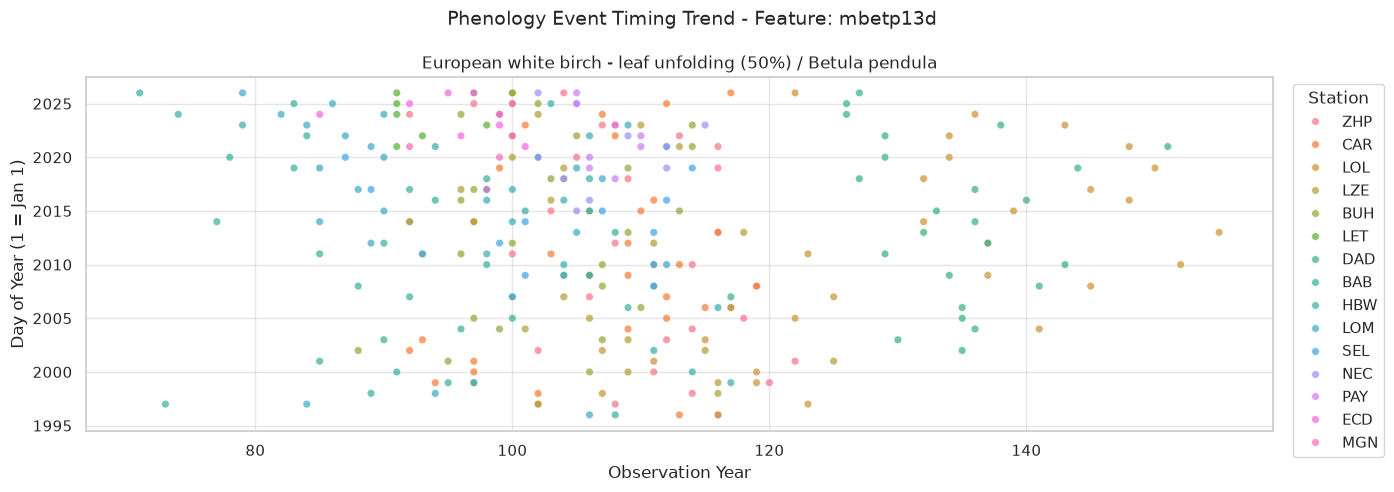

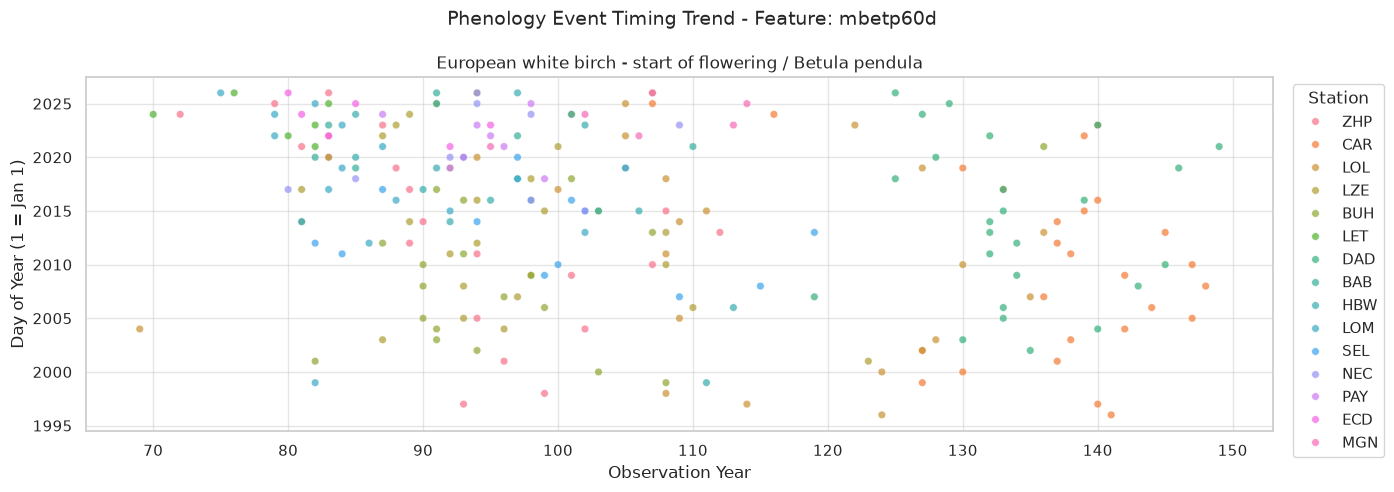

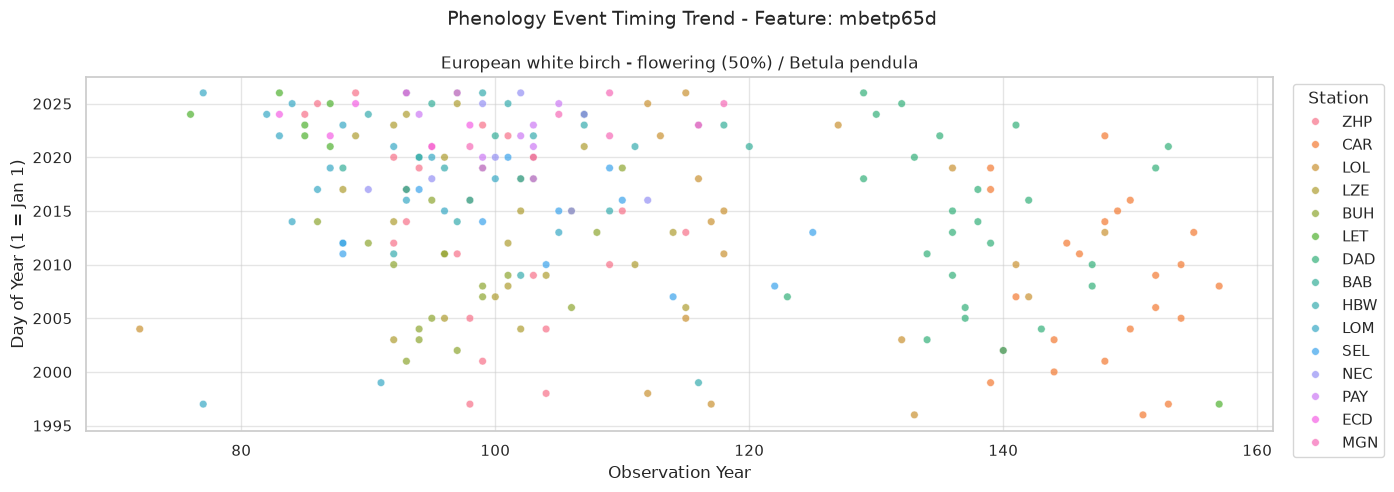

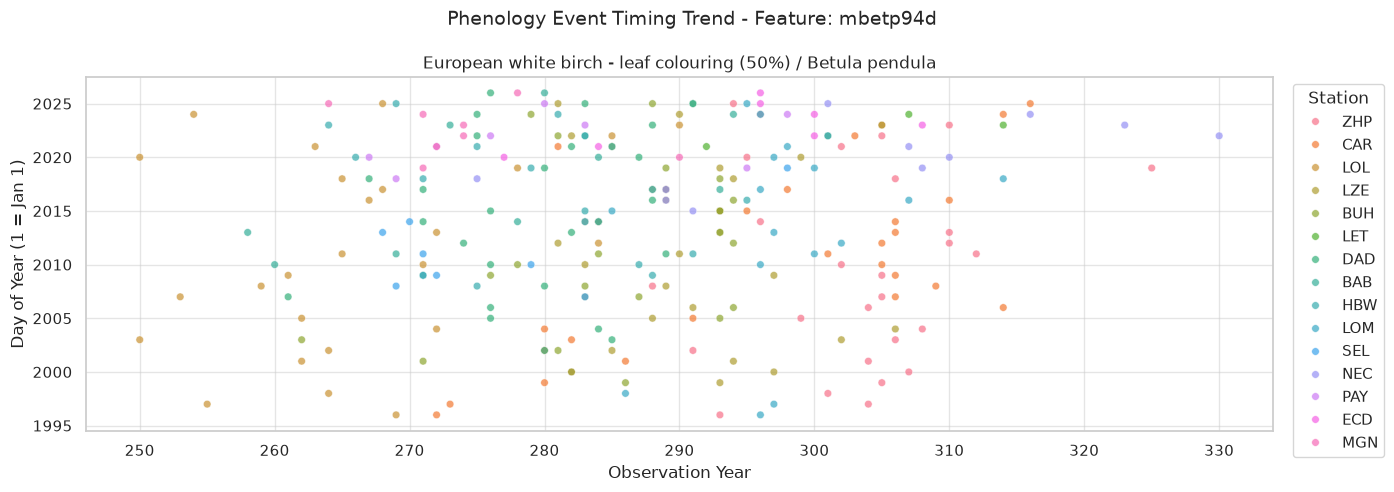

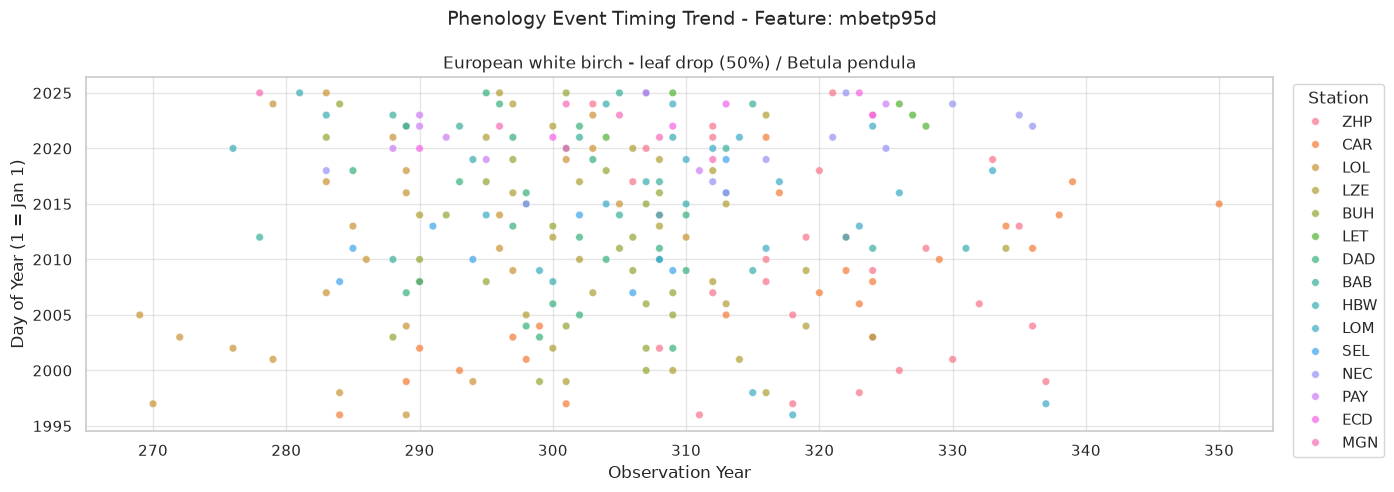

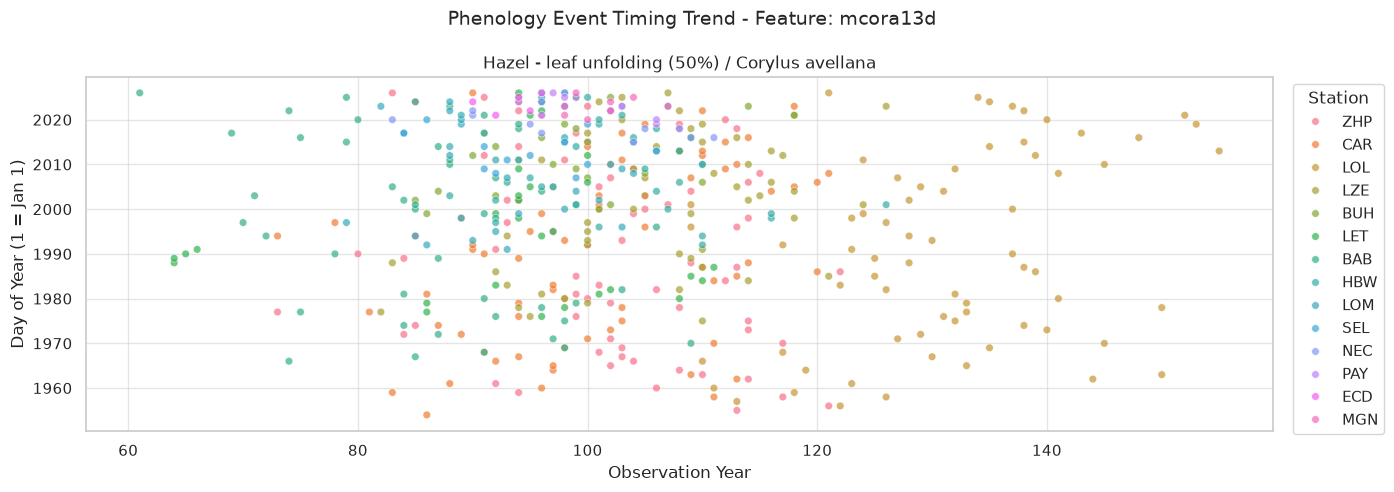

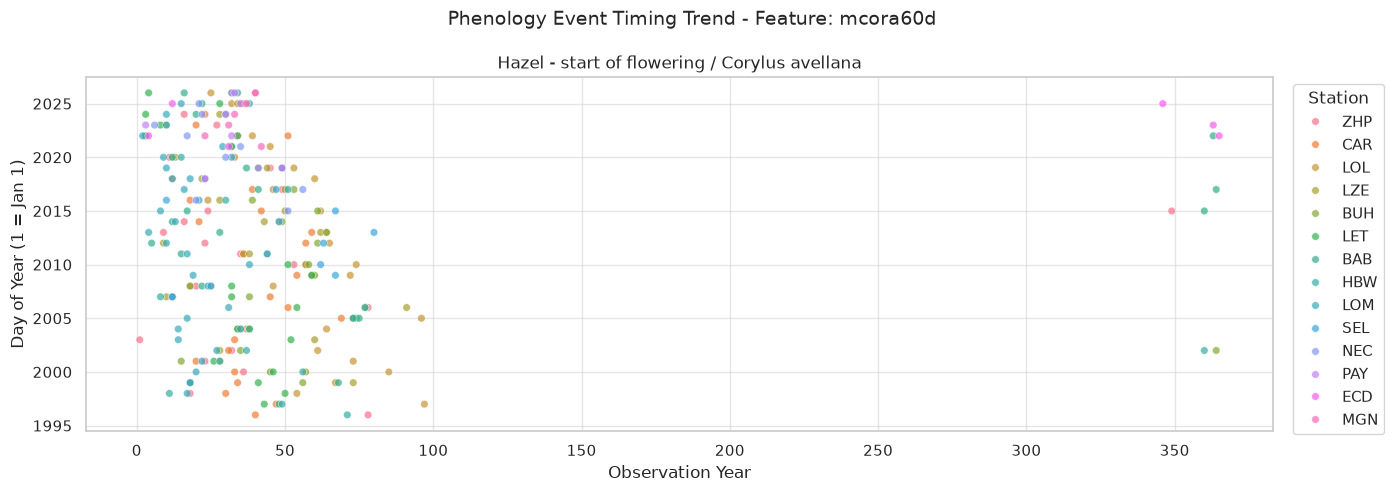

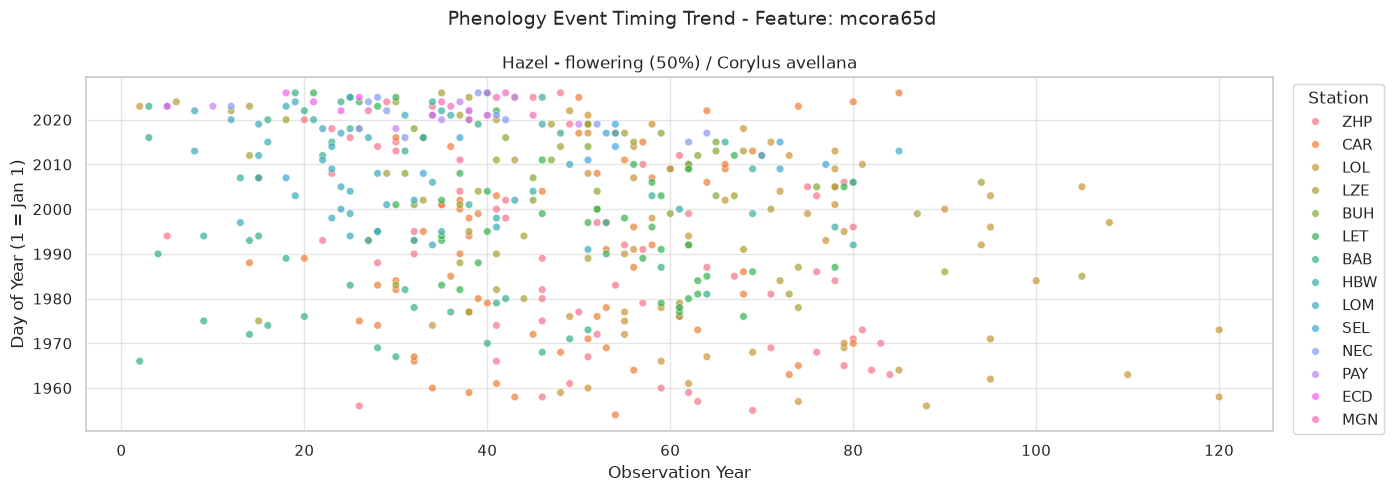

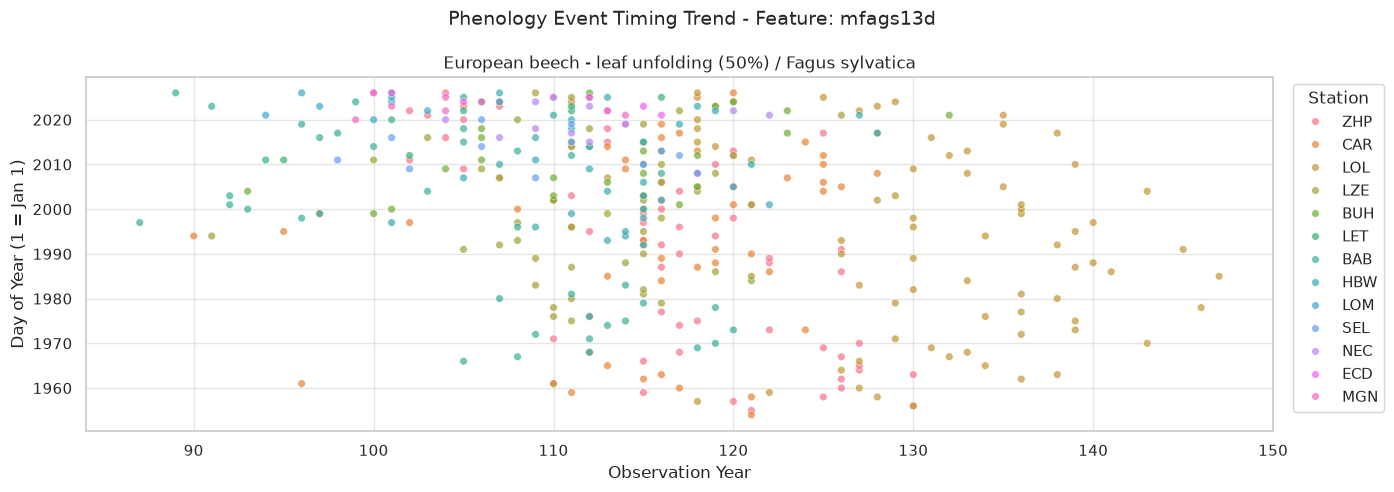

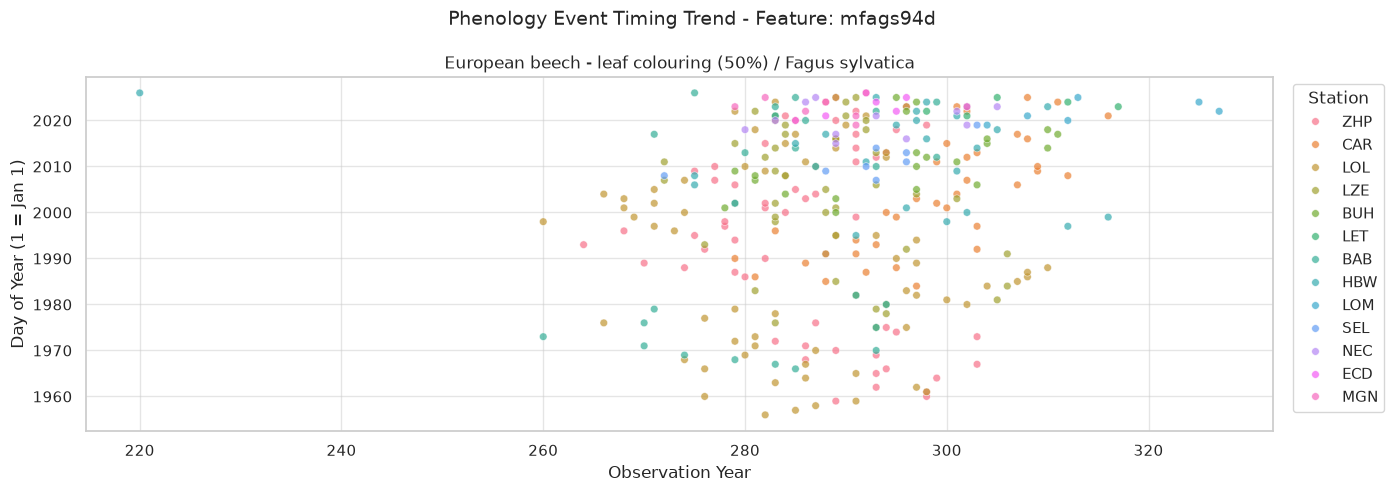

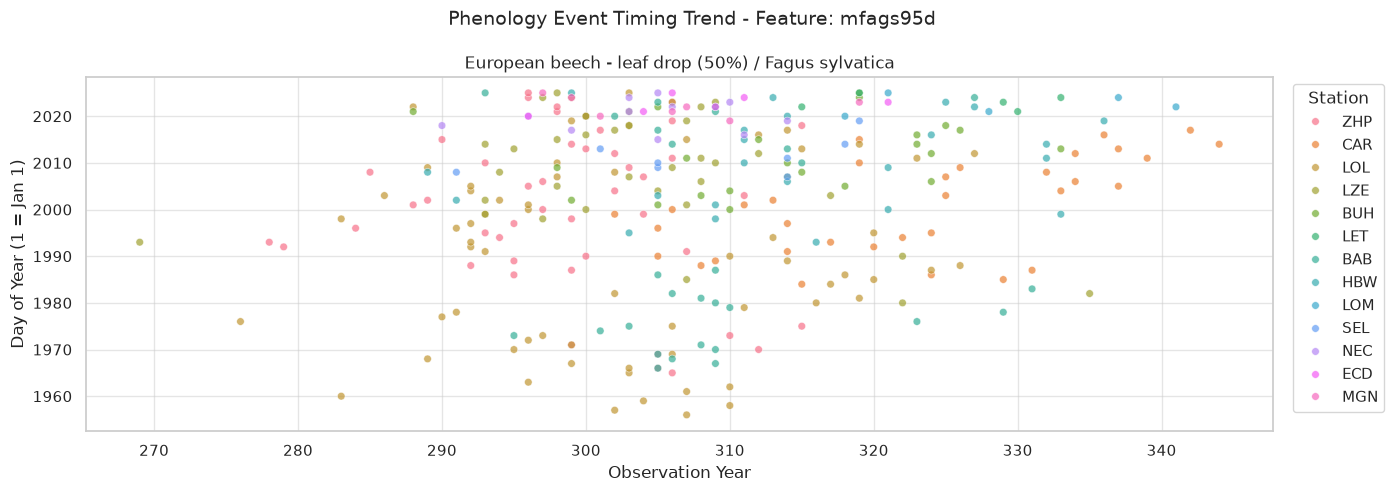

In [16]:
pheno_features = [
    'mbetp13d', 'mbetp60d', 'mbetp65d', 'mbetp94d', 'mbetp95d',
    'mcora13d', 'mcora60d', 'mcora65d',
    'mfags13d', 'mfags94d', 'mfags95d'
]

pdf_pheno = relevant_phenology_df.toPandas()

for feature in pheno_features:
    if feature not in pdf_pheno.columns:
        print(f"Skipping {feature}: not found in columns.")
        continue

    # 1. Drop rows where the feature is null
    df_plot = pdf_pheno.dropna(subset=[feature]).copy()
    if df_plot.empty:
        continue

    # 2. Fix float conversion issue: Convert to Int64 (preserves NaNs) -> int -> str
    # This strips the '.0' decimal suffix caused by missing values in numeric columns
    clean_date_series = df_plot[feature].dropna().astype('Int64').astype(str)

    # 3. Convert YYYYMMDD string to real datetime
    df_plot['event_date'] = pd.to_datetime(clean_date_series, format='%Y%m%d', errors='coerce')

    # 4. Drop rows where datetime parsing failed
    df_plot = df_plot.dropna(subset=['event_date'])

    if df_plot.empty:
        print(f"Skipping {feature}: no valid dates could be parsed.")
        continue

    # Extract observation year and day of the year safely
    df_plot['obs_year'] = df_plot['event_date'].dt.year
    df_plot['day_of_year'] = df_plot['event_date'].dt.day_of_year

    # 5. Create the plot
    plt.figure(figsize=(14, 5))
    sns.scatterplot(
        data=df_plot,
        x='day_of_year',
        y='obs_year',
        hue='station_abbr',
        alpha=0.7,
        s=30
    )

    plt.suptitle(f"Phenology Event Timing Trend - Feature: {feature}", fontsize=14)
    description = combined_params.loc[combined_params['parameter_shortname'] == feature, 'parameter_description_en'].values[0]
    plt.title(f"{description}", fontsize=12)
    plt.xlabel("Observation Year", fontsize=12)
    plt.ylabel("Day of Year (1 = Jan 1)", fontsize=12)
    plt.legend(bbox_to_anchor=(1.1, 1), loc="upper right", title="Station")
    plt.tight_layout()
    plt.show()

In [38]:
import ipywidgets as widgets
from IPython.display import display, clear_output

# 2. Prepare options
pheno_stations = sorted(pdf_pheno['station_abbr'].dropna().unique().tolist())
available_features = [f for f in pheno_features if f in pdf_pheno.columns]

# 3. Create Widgets
# Dropdown for selecting a single feature
feature_dropdown = widgets.Dropdown(
    options=available_features,
    value=available_features[0] if available_features else None,
    description='Feature:',
    disabled=False,
    style={'description_width': 'initial'}
)

# Create a dictionary of individual Checkbox widgets for each station
station_checkboxes = {
    station: widgets.Checkbox(value=True, description=station, indent=False)
    for station in pheno_stations
}

# Pack station checkboxes into a flexible wrapping box (or a scrollable grid)
stations_box = widgets.GridBox(
    list(station_checkboxes.values()),
    layout=widgets.Layout(grid_template_columns='repeat(5, 150px)', grid_gap='5px 10px')
)

# 4. Define the interactive plotting function
def plot_phenology_interactive(selected_feature, **station_vals):
   # Extract currently checked stations dynamically from the checkbox dictionary
    selected_stations = [st for st, cb in station_checkboxes.items() if cb.value]

    if not selected_stations:
        print("Please select at least one station.")
        return
    if not selected_feature:
        print("Please select a feature.")
        return

    # Filter dataframe by selected stations
    filtered_df = pdf_pheno[pdf_pheno['station_abbr'].isin(selected_stations)]

    df_plot = filtered_df.dropna(subset=[selected_feature]).copy()
    if df_plot.empty:
        print(f"No data available for feature '{selected_feature}' with the selected stations.")
        return

    # Safe date parsing
    clean_date_series = df_plot[selected_feature].dropna().astype('Int64').astype(str)
    df_plot['event_date'] = pd.to_datetime(clean_date_series, format='%Y%m%d', errors='coerce')
    df_plot = df_plot.dropna(subset=['event_date'])

    if df_plot.empty:
        print(f"No valid dates could be parsed for feature '{selected_feature}'.")
        return

    df_plot['obs_year'] = df_plot['event_date'].dt.year
    df_plot['day_of_year'] = df_plot['event_date'].dt.day_of_year

    # Fetch parameter description safely
    match = combined_params.loc[combined_params['parameter_shortname'] == selected_feature, 'parameter_description_en']
    description = match.values[0] if not match.empty else selected_feature

    # Render plot
    plt.figure(figsize=(15, 5))
    sns.scatterplot(
        data=df_plot,
        y='obs_year',
        x='day_of_year',
        hue='station_abbr',
        alpha=0.8,
        s=40
    )

    plt.suptitle(f"Phenology Trend Code: {selected_feature}", fontsize=14)
    plt.title(f"{description}", fontsize=12)
    plt.ylabel("Observation Year", fontsize=12)
    plt.xlabel("Day of Year (1 = Jan 1)", fontsize=12)
    plt.legend(bbox_to_anchor=(1.1, 1), loc="upper right", title="Station")
    plt.tight_layout()
    plt.show()

# 5. Link widgets using interactive_output (mapping checkboxes dynamically)
widget_mapping = {cb_name: cb_widget for cb_name, cb_widget in station_checkboxes.items()}
widget_mapping['selected_feature'] = feature_dropdown

out = widgets.interactive_output(plot_phenology_interactive, widget_mapping)

# 6. Display layout: Feature selection on top, followed by a clean grid of checkboxes
display(widgets.VBox([
    widgets.HTML("<h3>Interactive Phenology Explorer</h3>"),
    widgets.HBox([feature_dropdown]),  # Puts the dropdown cleanly in line
    widgets.HTML("<b>Select Stations:</b>"),
    stations_box,
    out
]))

In [18]:
def compute_all_pollen_season_metrics(spark_df, feature_cols=None, timestamp_col='reference_timestamp'):
    """
    Computes aerobiological season metrics (Integral, SOS 2.5%, Peak Day, EOS 97.5%)
    per station, year, and pollen feature.

    Parameters:
    - spark_df: PySpark DataFrame containing pollen data.
    - feature_cols: List of feature column names to compute metrics for.
                    If None, automatically detects numeric columns (excluding metadata).
    - timestamp_col: Name of the timestamp column.
    """
    # 1. Parse timestamps in PySpark
    df_parsed = spark_df.withColumn(
        "parsed_timestamp",
        F.to_timestamp(F.col(timestamp_col), "dd.MM.yyyy HH:mm")
    ).withColumn(
        "year", F.year("parsed_timestamp")
    ).withColumn(
        "doy", F.dayofyear("parsed_timestamp")
    )

    # 2. Automatically determine feature columns if not explicitly provided
    if feature_cols is None:
        exclude_cols = {'station_abbr', 'reference_timestamp', 'parsed_timestamp', 'year', 'doy'}
        feature_cols = [col for col in spark_df.columns if col not in exclude_cols]
    elif isinstance(feature_cols, str):
        feature_cols = [feature_cols]  # Support passing a single feature as a string

    # 3. Select columns and bring to Pandas for metric calculation loops
    cols_to_select = ['station_abbr', 'year', 'doy'] + feature_cols
    pdf_for_metrics = df_parsed.select(cols_to_select).toPandas()

    results = []

    # 4. Compute metrics independently for each feature across station and year groups
    for feature in feature_cols:
        if feature not in pdf_for_metrics.columns:
            continue

        for (station, year), group in pdf_for_metrics.groupby(['station_abbr', 'year']):
            group = group.sort_values('doy')
            concentrations = group[feature].fillna(0).values
            doy = group['doy'].values

            if len(concentrations) == 0 or np.sum(concentrations) == 0:
                continue

            # Cumulative Sum & Percentages
            cum_sum = np.cumsum(concentrations)
            total_integral = cum_sum[-1]

            if total_integral <= 0:
                continue

            cum_percent = (cum_sum / total_integral) * 100

            sos_idx = np.searchsorted(cum_percent, 2.5)
            peak_idx = np.argmax(concentrations)
            eos_idx = np.searchsorted(cum_percent, 97.5)

            sos_doy = doy[sos_idx] if sos_idx < len(doy) else np.nan
            peak_doy = doy[peak_idx]
            eos_doy = doy[eos_idx] if eos_idx < len(doy) else np.nan

            results.append({
                'station_abbr': station,
                'year': year,
                'feature': feature,
                'total_integral': total_integral,
                'SOS_2.5%': sos_doy,
                'Peak_Day': peak_doy,
                'EOS_97.5%': eos_doy,
                'Season_Length': (eos_doy - sos_doy) if not np.isnan(sos_doy) and not np.isnan(eos_doy) else np.nan
            })

    return pd.DataFrame(results)

df_all_metrics = compute_all_pollen_season_metrics(pollen_df)

/home/Binny/Projects/Pollen/.venv/lib64/python3.12/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


In [ ]:
from IPython.display import clear_output, display
import ipywidgets as widgets

def plot_interactive_station_gridbox(df, feature_name):
  """Automatically extracts all stations, arranges checkboxes in a GridBox layout,

  checks only the first station by default, and updates the plot dynamically.
  """
  # Automatically extract all unique stations and sort them
  stations_list = sorted(df['station_abbr'].unique())

  if not stations_list:
    print('No stations found in the dataframe.')
    return

  # Create a dictionary of Checkboxes: only the first station is checked by default
  station_checkboxes = {}
  for i, station in enumerate(stations_list):
    is_checked = i == 0  # True for the first station, False for all others
    station_checkboxes[station] = widgets.Checkbox(
        value=is_checked,
        description=str(station),
        indent=False,
        layout=widgets.Layout(width='140px'),
    )

  # Create an output container to hold and refresh the plot
  out = widgets.Output()

  def update_plot(change=None):
    with out:
      clear_output(wait=True)  # Clear the previous plot

      # Gather currently checked stations
      selected_stations = [
          station for station, cb in station_checkboxes.items() if cb.value
      ]

      if not selected_stations:
        print('Please select at least one station using the checkboxes above.')
        return

      # Filter dataframe based on active checkboxes
      filtered_df = df[
          (df['feature'] == feature_name)
          & (df['station_abbr'].isin(selected_stations))
      ]

      if filtered_df.empty:
        print('No data available for the selected stations.')
        return

      # Melt metrics for Seaborn semantic mapping
      metrics = ['SOS_2.5%', 'Peak_Day', 'EOS_97.5%', 'Season_Length']
      df_melted = filtered_df.melt(
          id_vars=['station_abbr', 'year', 'feature'],
          value_vars=metrics,
          var_name='Metric',
          value_name='Value',
      )

      # Generate figure and Seaborn line plot
      plt.figure(figsize=(12, 6))
      sns.lineplot(
          data=df_melted,
          x='year',
          y='Value',
          hue='station_abbr',
          style='Metric',
          markers=True,
          dashes=False,
          alpha=0.85,
          # linewidth=1,
          # markersize=6,
      )

      match = combined_params.loc[combined_params['parameter_shortname'] == feature_name, 'parameter_description_en']
      description = match.values[0] if not match.empty else feature_name
      plt.suptitle(f'Seasonal Metrics Overview for Feature: {feature_name}', fontsize=14, fontweight='bold')
      plt.title(f"{description}", fontsize=12)
      plt.xlabel('Year', fontsize=11, fontweight='bold')
      plt.ylabel('Value / DOY', fontsize=11, fontweight='bold')
      plt.grid(True, linestyle='--', alpha=0.5)

      # Position legend outside the plot area
      plt.legend(
          bbox_to_anchor=(1.02, 1),
          loc='upper left',
          frameon=True,
          fontsize=8,
          title='Station & Metric',
      )

      plt.tight_layout()
      plt.show()

  # Attach the update callback to every checkbox change event
  for cb in station_checkboxes.values():
    cb.observe(update_plot, names='value')

  # Arrange checkboxes cleanly using your GridBox layout inside a scrollable container
  stations_box = widgets.GridBox(
      list(station_checkboxes.values()),
      layout=widgets.Layout(
          grid_template_columns='repeat(5, 150px)', grid_gap='5px 10px'
      ),
  )

  controls_ui = widgets.VBox(
      [
          widgets.Label(
              'Toggle Stations:',
              style={'font_weight': 'bold'},
          ),
          widgets.Box(
              [stations_box],
              layout=widgets.Layout(
                  max_height='160px',
                  overflow_y='auto',
                  border='1px solid #ddd',
                  padding='8px',
              ),
          ),
      ]
  )

  # Display controls and output container together
  display(widgets.VBox([controls_ui, out]))

  # Render initial plot on load
  update_plot()

# Example call with your dataframe, a sample feature, and a list of stations
selected_stations = sorted(df_all_metrics['station_abbr'].dropna().unique().tolist())#['PBE', 'PBU']
plot_interactive_station_gridbox(df=df_all_metrics, feature_name='kaalnud0')